In [ ]:
import sklearn.datasets as ds
import sklearn.ensemble as es
import sklearn.tree as tree
import sklearn.model_selection as ms
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
def draw_area(x,y,model):
  # 1. 그래프의 x,y 축의 범위 설정
  x_min,x_max = x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max = x[:,1].min()-1, x[:,1].max()+1

  # 2. 만든 범위를 0.01 간격으로 촘촘한 값을 생성
  pos_x = np.arange(x_min,x_max,0.01)
  pos_y = np.arange(y_min,y_max,0.01)
  # print(f'pos X : {pos_x}')
  # print(f'pos Y : {pos_y}')

  # 3. 격자 형태로 x,y 배열을 만든다.
  xx,yy = np.meshgrid(pos_x, pos_y)

  # 4. 두 배열을 합쳐서 일렬로 만들어 준다.
  # 두 배열을 합칠때 각각 1차원 이어야 하는데 xx, yy 는 2차원이다.
  # 그래서 ravel() 함수를 통해 1차원으로 만든다.
  val = np.c_[xx.ravel(),yy.ravel()]
  # print(val) # [[x,y],[x,y],...]

  # 5. 이렇게 생성된 값으로 모델에 예측을 시킨다.
  z = model.predict(val)
  print(z)

  # 6. 영역을 그려준다.
  plt.scatter(x[:,0],x[:,1])
  plt.contourf(xx,yy,z.reshape(xx.shape),alpha=0.3)
  plt.show()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
score : 0.9533333333333334
estimators : [DecisionTreeClassifier(max_depth=3, random_state=239442143), DecisionTreeClassifier(max_depth=3, random_state=2099108645), DecisionTreeClassifier(max_depth=3, random_state=324659252), DecisionTreeClassifier(max_depth=3, random_state=1514537663), DecisionTreeClassifier(max_depth=3, random_state=1446531787)]
[0 0 0 ... 2 2 2]


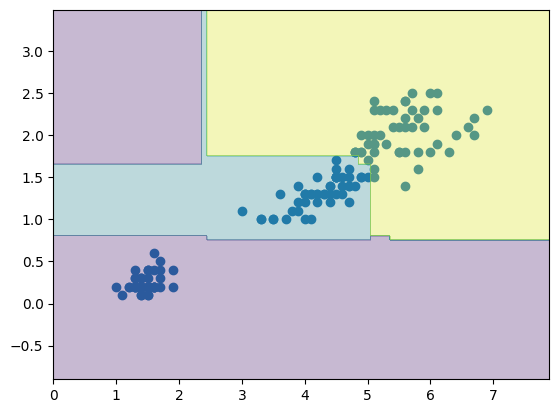

In [ ]:
iris = ds.load_iris()
print(iris.keys())
print(iris.feature_names)

x = iris.data[:,[2,3]]
y = iris.target

# 동일 모델을 n 개 만들어서 다수결로 의사결정 한다.
# model, random_state, n_estimators
bagg = es.BaggingClassifier(
    tree.DecisionTreeClassifier(max_depth=3, random_state=7),
    random_state=7,
    n_estimators=5
).fit(x,y)

score = ms.cross_val_score(bagg,x,y,cv=5)
print(f'score : {score.mean()}')
print(f'estimators : {bagg.estimators_}')
draw_area(x,y,bagg)